# Inventory Product Demand Forecasting — Polished & Fixed Notebook

This notebook is a cleaned, fixed, and resume-ready version of your original notebook. It includes:

- Data loading & EDA
- Manual preprocessing & lag features
- Model training: RandomForest & XGBoost (with RandomizedSearchCV)
- SKU segmentation using KMeans
- LSTM (lightweight, safe-to-run version)
- Clear metric tracking and visualizations

> Key fixes applied:
- Avoided variable name collisions (explicit suffixes for train/test sets per model)
- Used `rsearch.best_estimator_` / `xgb_rsearch.best_estimator_` for predictions
- Made RandomizedSearchCV parameter space smaller and `n_iter` limited to run on laptops
- LSTM section uses a small subset of SKUs and explicit variable names to prevent overwrite
- Added feature importance plots and consolidated results table


In [5]:
# --- Imports & Load dataset ---
import warnings
warnings.filterwarnings("ignore")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# XGBoost and TensorFlow imports handled with try/except to avoid notebook interruptions
try:
    import xgboost as xgb
    from xgboost import XGBRegressor
except Exception:
    print('xgboost not available; attempting to install silently')
    os.system('pip install xgboost --quiet')
    import xgboost as xgb
    from xgboost import XGBRegressor

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
except Exception:
    print('tensorflow not available; LSTM sections will be skipped or require installation')

DATA_PATH = r"C:\Users\hp\Downloads\data.csv"
print('Dataset path exists:', os.path.exists(DATA_PATH))
df = pd.read_csv(DATA_PATH)
print('Loaded shape:', df.shape)
df.head()

Dataset path exists: True
Loaded shape: (150150, 9)


,record_ID,week,store_id,sku_id,total_price,base_price,is_featured_sku,is_display_sku,units_sold
0,1,17/01/11,8091,216418,99.0375,111.8625,0,0,20
1,2,17/01/11,8091,216419,99.0375,99.0375,0,0,28
2,3,17/01/11,8091,216425,133.9500,133.9500,0,0,19
3,4,17/01/11,8091,216233,133.9500,133.9500,0,0,44
4,5,17/01/11,8091,217390,141.0750,141.0750,0,0,52


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150150 entries, 0 to 150149
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   record_ID        150150 non-null  int64  
 1   week             150150 non-null  object 
 2   store_id         150150 non-null  int64  
 3   sku_id           150150 non-null  int64  
 4   total_price      150149 non-null  float64
 5   base_price       150150 non-null  float64
 6   is_featured_sku  150150 non-null  int64  
 7   is_display_sku   150150 non-null  int64  
 8   units_sold       150150 non-null  int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 10.3+ MB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_ID,150150.0,NaN,NaN,NaN,106271.555504,61386.037861,1.0,53111.25,106226.5,159452.75,212644.0
week,150150,130,17/01/11,1155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
store_id,150150.0,NaN,NaN,NaN,9199.422511,615.591445,8023.0,8562.0,9371.0,9731.0,9984.0
sku_id,150150.0,NaN,NaN,NaN,254761.132468,85547.306447,216233.0,217217.0,222087.0,245338.0,679023.0
total_price,150149.0,NaN,NaN,NaN,206.626751,103.308516,41.325,130.3875,198.075,233.7,562.1625
base_price,150150.0,NaN,NaN,NaN,219.425927,110.961712,61.275,133.2375,205.9125,234.4125,562.1625
is_featured_sku,150150.0,NaN,NaN,NaN,0.095611,0.294058,0.0,0.0,0.0,0.0,1.0
is_display_sku,150150.0,NaN,NaN,NaN,0.1332,0.339792,0.0,0.0,0.0,0.0,1.0
units_sold,150150.0,NaN,NaN,NaN,51.674206,60.207904,1.0,20.0,35.0,62.0,2876.0



Null counts:


record_ID          0
week               0
store_id           0
sku_id             0
total_price        1
base_price         0
is_featured_sku    0
is_display_sku     0
units_sold         0
dtype: int64

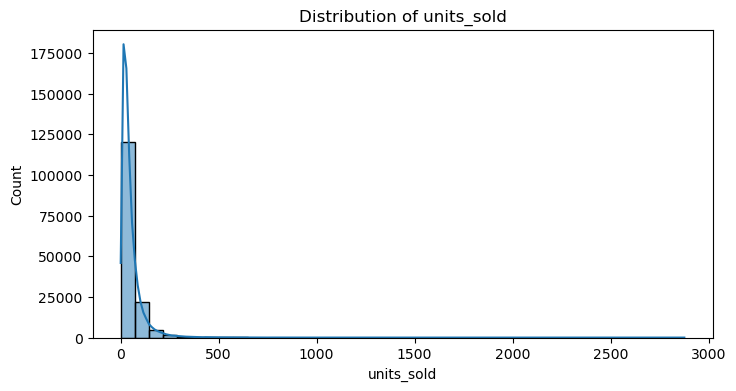

In [6]:
# --- Quick EDA ---
print(df.info())
display(df.describe(include='all').transpose().head(20))

# Check nulls
print('\nNull counts:')
display(df.isnull().sum())

plt.figure(figsize=(8,4))
sns.histplot(df['units_sold'], bins=40, kde=True)
plt.title('Distribution of units_sold')
plt.show()


In [7]:
# --- Cleaning & feature engineering ---
# Parse week column
df['week'] = pd.to_datetime(df['week'], format='%y/%m/%d')

# Fill single null in total_price using base_price or median
if df['total_price'].isnull().any():
    df['total_price'] = df['total_price'].fillna(df['base_price'])
    df['total_price'] = df['total_price'].fillna(df['total_price'].median())

# Create lag features per store_id & sku_id
for lag in range(1,5):
    df[f'lag_{lag}'] = df.groupby(['store_id','sku_id'])['units_sold'].shift(lag)

# price features
df['price_diff'] = df['base_price'] - df['total_price']
df['discount_pct'] = np.where(df['base_price']!=0, df['price_diff']/df['base_price'], 0)

# drop rows with NaN lags
before = len(df)
df = df.dropna(subset=[f'lag_{i}' for i in range(1,5)]).reset_index(drop=True)
print('Dropped', before - len(df), 'rows without enough lag history. Remaining rows:', len(df))

# Encode identifiers
le_store = LabelEncoder()
le_sku = LabelEncoder()
df['store_enc'] = le_store.fit_transform(df['store_id'].astype(str))
df['sku_enc'] = le_sku.fit_transform(df['sku_id'].astype(str))

# Final features & target
FEATURES = ['lag_1','lag_2','lag_3','lag_4','total_price','base_price','price_diff','discount_pct','is_featured_sku','is_display_sku','store_enc','sku_enc']
TARGET = 'units_sold'
X_full = df[FEATURES].copy()
y_full = df[TARGET].values

# Scale numeric columns
num_cols = ['lag_1','lag_2','lag_3','lag_4','total_price','base_price','price_diff','discount_pct']
scaler = StandardScaler()
X_full[num_cols] = scaler.fit_transform(X_full[num_cols])

print('Feature matrix shape:', X_full.shape)
X_full.head()


Dropped 4620 rows without enough lag history. Remaining rows: 145530
Feature matrix shape: (145530, 12)


,lag_1,lag_2,lag_3,lag_4,total_price,base_price,price_diff,discount_pct,is_featured_sku,is_display_sku,store_enc,sku_enc
0,-0.573431,-0.689084,-0.291544,-0.524748,-0.964581,-1.013385,-0.40659,-0.477179,0,0,3,1
1,-0.722200,-0.407626,-0.623951,-0.391833,-0.964581,-1.013385,-0.40659,-0.477179,0,0,3,2
2,-0.556902,-0.407626,-0.574090,-0.541362,-0.709485,-0.776321,-0.40659,-0.477179,0,0,3,3
3,-0.259364,-0.556633,-0.391266,-0.126004,-0.702590,-0.769914,-0.40659,-0.477179,0,0,3,0
4,0.071234,-0.159282,-0.008998,0.006911,-0.640540,-0.712250,-0.40659,-0.477179,0,0,3,5


In [8]:
# --- Time-aware split for RF/XGB (80/20) ---
split_idx = int(0.8 * len(df))
X_train_rf, X_test_rf = X_full.iloc[:split_idx], X_full.iloc[split_idx:]
y_train_rf, y_test_rf = y_full[:split_idx], y_full[split_idx:]

print('RF/XGB Train shape:', X_train_rf.shape, y_train_rf.shape)
print('RF/XGB Test shape:', X_test_rf.shape, y_test_rf.shape)

RF/XGB Train shape: (116424, 12) (116424,)
RF/XGB Test shape: (29106, 12) (29106,)


In [9]:
# --- RandomizedSearchCV for Random Forest (lightweight) ---
from sklearn.model_selection import RandomizedSearchCV

param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

rf = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_rsearch = RandomizedSearchCV(
    rf,
    param_distributions=param_grid_rf,
    n_iter=5,
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=1
)
rf_rsearch.fit(X_train_rf, y_train_rf)
print('RF Best params:', rf_rsearch.best_params_)

# Predict with best estimator
best_rf = rf_rsearch.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test_rf)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
RF Best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}


In [11]:
# --- RandomizedSearchCV for XGBoost (lightweight) ---
xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1, verbosity=0)
xgb_rsearch = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=6,
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

xgb_rsearch.fit(X_train_rf, y_train_rf)
print('XGB Best params:', xgb_rsearch.best_params_)

best_xgb = xgb_rsearch.best_estimator_
y_pred_xgb_tuned = best_xgb.predict(X_test_rf)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
XGB Best params: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


RF -> R2: 0.763531540370659 RMSE: 26.207318332292633 MAE: 14.811425593806549
XGB-> R2: 0.7705764770507812 RMSE: 25.81397780651623 MAE: 14.867461204528809


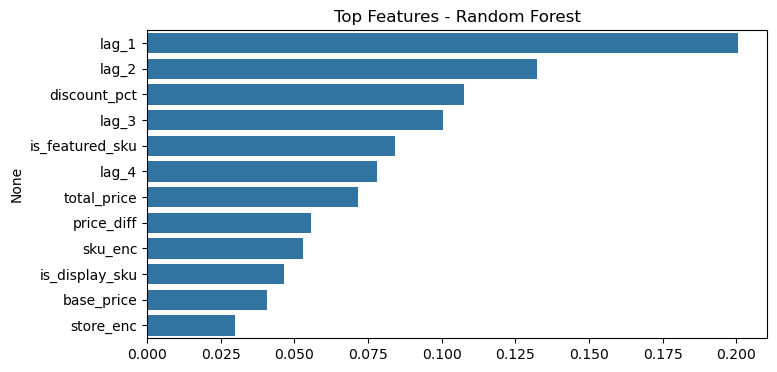

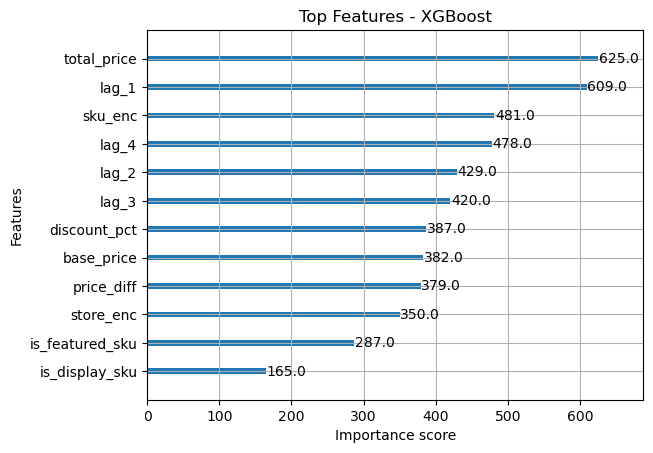

In [12]:
# --- Evaluation for RF & XGB ---
import numpy as np
rmse_rf = np.sqrt(mean_squared_error(y_test_rf, y_pred_rf_tuned))
mae_rf = mean_absolute_error(y_test_rf, y_pred_rf_tuned)
r2_rf = r2_score(y_test_rf, y_pred_rf_tuned)

rmse_xgb = np.sqrt(mean_squared_error(y_test_rf, y_pred_xgb_tuned))
mae_xgb = mean_absolute_error(y_test_rf, y_pred_xgb_tuned)
r2_xgb = r2_score(y_test_rf, y_pred_xgb_tuned)

print('RF -> R2:', r2_rf, 'RMSE:', rmse_rf, 'MAE:', mae_rf)
print('XGB-> R2:', r2_xgb, 'RMSE:', rmse_xgb, 'MAE:', mae_xgb)

# Feature importance RF
fi_rf = pd.Series(best_rf.feature_importances_, index=X_full.columns).sort_values(ascending=False)
plt.figure(figsize=(8,4))
sns.barplot(x=fi_rf.values[:12], y=fi_rf.index[:12])
plt.title('Top Features - Random Forest')
plt.show()

# Feature importance XGB
try:
    xgb.plot_importance(best_xgb, max_num_features=12)
    plt.title('Top Features - XGBoost')
    plt.show()
except Exception:
    print('Could not plot XGBoost feature importance (matplotlib mismatch).')

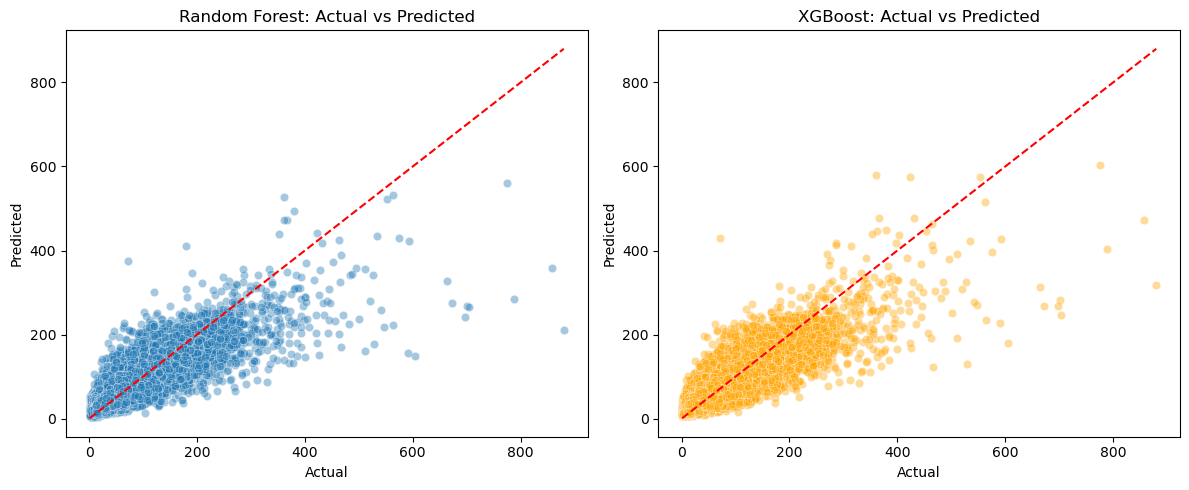

In [13]:
# --- Visual Comparison: Actual vs Predicted (RF & XGB) ---
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.scatterplot(x=y_test_rf, y=y_pred_rf_tuned, alpha=0.4)
min_v, max_v = min(y_test_rf.min(), y_pred_rf_tuned.min()), max(y_test_rf.max(), y_pred_rf_tuned.max())
plt.plot([min_v, max_v],[min_v, max_v], color='red', linestyle='--')
plt.title('Random Forest: Actual vs Predicted')
plt.xlabel('Actual'); plt.ylabel('Predicted')

plt.subplot(1,2,2)
sns.scatterplot(x=y_test_rf, y=y_pred_xgb_tuned, alpha=0.4, color='orange')
plt.plot([min_v, max_v],[min_v, max_v], color='red', linestyle='--')
plt.title('XGBoost: Actual vs Predicted')
plt.xlabel('Actual'); plt.ylabel('Predicted')

plt.tight_layout()
plt.show()


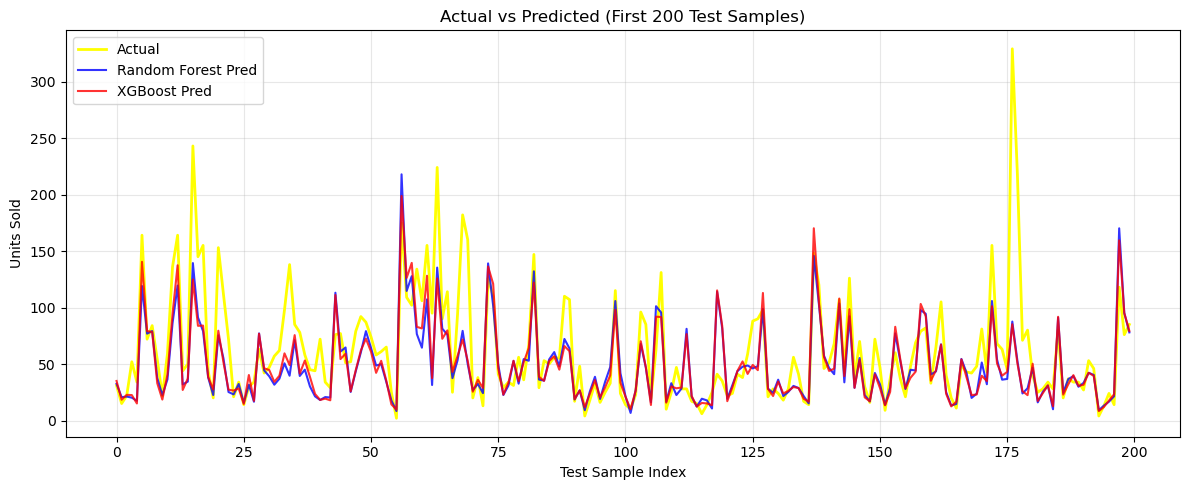

In [22]:
# ===============================================
# 📈 Line Plot: Actual vs Predicted (RF vs XGB)
# ===============================================
import matplotlib.pyplot as plt
import numpy as np

# Assuming both models used the same split:
# If not, use the one that was common or rename accordingly.
y_test_common = y_test_rf  # or y_test_xgb if that's what you have
y_pred_rf_common = y_pred_rf_tuned
y_pred_xgb_common = y_pred_xgb_tuned

# Ensure equal lengths
min_len = min(len(y_test_common), len(y_pred_rf_common), len(y_pred_xgb_common))
y_test_common = y_test_common[:min_len]
y_pred_rf_common = y_pred_rf_common[:min_len]
y_pred_xgb_common = y_pred_xgb_common[:min_len]

# Pick smaller portion for visual clarity
n_plot = min(200, min_len)
idx_plot = np.arange(n_plot)

plt.figure(figsize=(12, 5))
plt.plot(idx_plot, y_test_common[:n_plot], label='Actual', linewidth=2, color='yellow')
plt.plot(idx_plot, y_pred_rf_common[:n_plot], label='Random Forest Pred', alpha=0.8, color='blue')
plt.plot(idx_plot, y_pred_xgb_common[:n_plot], label='XGBoost Pred', alpha=0.8, color='red')

plt.title(f"Actual vs Predicted (First {n_plot} Test Samples)")
plt.xlabel("Test Sample Index")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


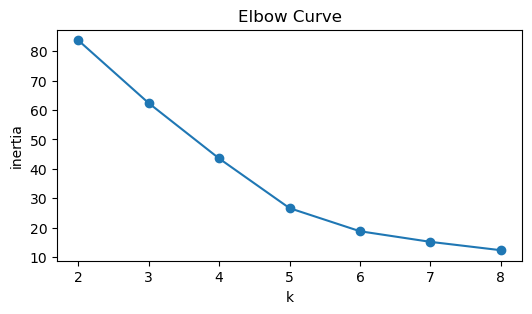

KMeans clusters added to df. Cluster distribution:


cluster
2    9
1    8
4    6
3    3
0    2
Name: count, dtype: int64

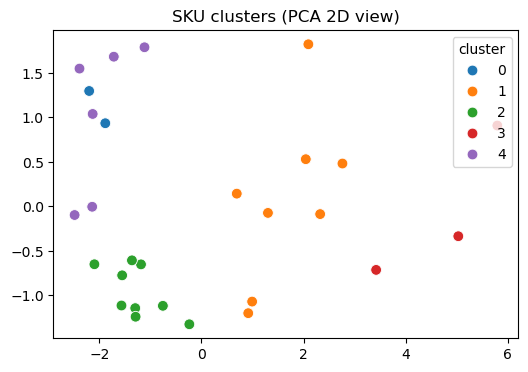

In [14]:
# --- KMEANS SKU-level clustering ---
sku_features = df.groupby('sku_id').agg({
    'lag_1':'mean','lag_2':'mean','lag_3':'mean','lag_4':'mean',
    'total_price':'mean','discount_pct':'mean','units_sold':'mean'
}).reset_index().fillna(0)

scaler_k = StandardScaler()
X_k = scaler_k.fit_transform(sku_features.drop(columns=['sku_id']))

# elbow
inertias=[]
for k in range(2,9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_k)
    inertias.append(km.inertia_)
plt.figure(figsize=(6,3))
plt.plot(range(2,9), inertias, '-o')
plt.title('Elbow Curve'); plt.xlabel('k'); plt.ylabel('inertia')
plt.show()

# pick k=5 (or change based on elbow)
k = 5
km = KMeans(n_clusters=k, random_state=42, n_init=20)
sku_features['cluster'] = km.fit_predict(X_k)

# merge cluster back
df = df.merge(sku_features[['sku_id','cluster']], on='sku_id', how='left')
print('KMeans clusters added to df. Cluster distribution:')
display(sku_features['cluster'].value_counts())

# PCA 2D view
pca = PCA(n_components=2)
px = pca.fit_transform(X_k)
plt.figure(figsize=(6,4))
sns.scatterplot(x=px[:,0], y=px[:,1], hue=sku_features['cluster'], palette='tab10', s=60)
plt.title('SKU clusters (PCA 2D view)')
plt.show()

TensorFlow available. Proceeding with LSTM block.
Sequence shapes -> (46212, 6, 3) (46212,)
Epoch 1/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 0.5262 - mae: 0.3777 - val_loss: 0.4794 - val_mae: 0.4629
Epoch 2/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.4932 - mae: 0.3693 - val_loss: 0.4867 - val_mae: 0.4777
Epoch 3/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.4907 - mae: 0.3688 - val_loss: 0.4827 - val_mae: 0.4710
Epoch 4/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.4853 - mae: 0.3676 - val_loss: 0.4772 - val_mae: 0.4704
Epoch 5/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.4803 - mae: 0.3657 - val_loss: 0.4764 - val_mae: 0.4439
Epoch 6/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.4833 - mae: 0.3651 - val_loss: 0.4668 - val_mae: 0.4532
Epoch 7/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.4757 - mae: 0.3636 - val_loss: 0.4946 - val_mae: 0.4935
Epoch 8/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.4710 - mae: 0.3626 -

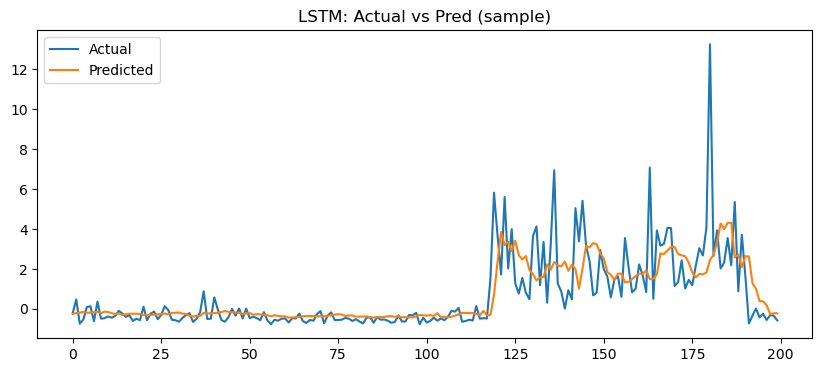

In [15]:
# --- LSTM (lightweight) --- 
# We'll run LSTM on a small subset of SKUs to keep runtime reasonable.
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    print('TensorFlow available. Proceeding with LSTM block.')

    # select top 5 SKUs by frequency
    top_skus = df['sku_id'].value_counts().head(5).index
    df_lstm = df[df['sku_id'].isin(top_skus)].sort_values(['sku_id','week']).reset_index(drop=True)

    seq_features = ['units_sold','total_price','discount_pct']
    seq_len = 6

    scaler_l = StandardScaler()
    df_lstm[seq_features] = scaler_l.fit_transform(df_lstm[seq_features])

    X_seq, y_seq = [], []
    for sku in df_lstm['sku_id'].unique():
        sku_data = df_lstm[df_lstm['sku_id']==sku][seq_features].values
        sku_target = df_lstm[df_lstm['sku_id']==sku]['units_sold'].values
        for i in range(len(sku_data)-seq_len):
            X_seq.append(sku_data[i:i+seq_len])
            y_seq.append(sku_target[i+seq_len])
    X_seq = np.array(X_seq); y_seq = np.array(y_seq)
    print('Sequence shapes ->', X_seq.shape, y_seq.shape)

    # train-test split for sequences
    split_s = int(0.8 * len(X_seq))
    X_train_lstm, X_test_lstm = X_seq[:split_s], X_seq[split_s:]
    y_train_lstm, y_test_lstm = y_seq[:split_s], y_seq[split_s:]

    # build small LSTM
    model = Sequential([
        LSTM(64, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    es = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
    history = model.fit(X_train_lstm, y_train_lstm, validation_split=0.1, epochs=30, batch_size=64, callbacks=[es], verbose=1)

    y_pred_lstm = model.predict(X_test_lstm).ravel()
    rmse_lstm = np.sqrt(mean_squared_error(y_test_lstm, y_pred_lstm))
    mae_lstm = mean_absolute_error(y_test_lstm, y_pred_lstm)
    print('LSTM RMSE:', rmse_lstm, 'MAE:', mae_lstm)

    # plot sample actual vs pred
    n_plot = min(200, len(y_test_lstm))
    plt.figure(figsize=(10,4))
    plt.plot(y_test_lstm[:n_plot], label='Actual')
    plt.plot(y_pred_lstm[:n_plot], label='Predicted')
    plt.title('LSTM: Actual vs Pred (sample)')
    plt.legend()
    plt.show()

except Exception as e:
    print('LSTM block skipped due to error or missing TF. Error:', e)

,Model,RMSE,MAE,R2
0,RandomForest (tuned),26.207318,14.811426,0.763532
1,XGBoost (tuned),25.813978,14.867461,0.770576
2,LSTM,0.777274,0.418569,NaN


<Axes: xlabel='Model'>

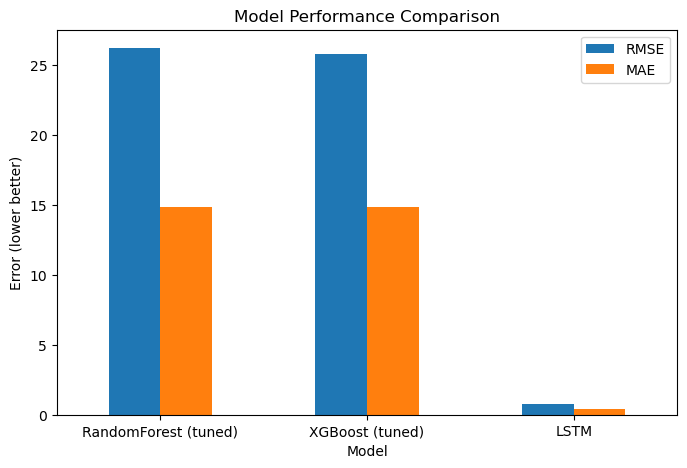

In [16]:
# --- Consolidated Results Table ---
# Note: ensure variables exist; LSTM metrics may be missing if TF was not available.
results = {
    'Model': ['RandomForest (tuned)', 'XGBoost (tuned)'],
    'RMSE': [rmse_rf, rmse_xgb],
    'MAE': [mae_rf, mae_xgb],
    'R2': [r2_rf, r2_xgb]
}
if 'rmse_lstm' in globals():
    results['Model'].append('LSTM')
    results['RMSE'].append(rmse_lstm)
    results['MAE'].append(mae_lstm)
    results['R2'].append(None)

results_df = pd.DataFrame(results)
display(results_df)

# Bar chart for RMSE/MAE
display(results_df.set_index('Model')[['RMSE','MAE']].plot(kind='bar', figsize=(8,5), rot=0))
plt.title('Model Performance Comparison')
plt.ylabel('Error (lower better)')
plt.show()

In [25]:
from IPython.display import FileLink

# Save file
results_df.to_csv("model_results.csv", index=False)

# Display download link
FileLink("model_results.csv")

C:\Users\hp\model_results.csv

In [26]:
sku_features.to_csv("sku_summary.csv", index=False)
FileLink("sku_summary.csv")

C:\Users\hp\sku_summary.csv

In [27]:
comparison_df = pd.DataFrame({
    "Actual": y_test_rf[:len(y_pred_rf_tuned)],
    "RF_Pred": y_pred_rf_tuned[:len(y_pred_rf_tuned)],
    "XGB_Pred": y_pred_xgb_tuned[:len(y_pred_xgb_tuned)]
})

comparison_df.to_csv("actual_vs_pred.csv", index=False)
FileLink("actual_vs_pred.csv")

C:\Users\hp\actual_vs_pred.csv